In [4]:
# Install required libraries if running locally or in a fresh Colab environment
!pip install datasets gradio matplotlib torch

import torch
import torch.nn as nn
from torch.nn import functional as F
from datasets import load_dataset
import matplotlib.pyplot as plt
import time

# Set random seed for reproducibility
torch.manual_seed(1337)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"using device: {device}")

using device: cuda


In [5]:
# 1. Load the roneneldan/TinyStories dataset from Hugging Face
print("Loading TinyStories dataset...")
dataset = load_dataset("roneneldan/TinyStories", split="train", streaming=False)

# Select a small subset of stories for efficient training in Colab
subset_size = 5000
raw_stories = dataset["text"][:subset_size]

print(f"Loaded {len(raw_stories)} stories.")

# Explore dataset: Display several stories and check lengths
print("\n--- Sample Stories & Length Analysis ---")
lengths = [len(story) for story in raw_stories]
avg_length = sum(lengths) / len(lengths)

for i in range(3):
    print(f"\n[Story {i+1} | Length: {len(raw_stories[i])} characters]:")
    print(raw_stories[i][:300] + "..." if len(raw_stories[i]) > 300 else raw_stories[i])

print(f"\nAverage story length: {avg_length:.2f} characters.")

Loading TinyStories dataset...


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

... (5 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Loaded 5000 stories.

--- Sample Stories & Length Analysis ---

[Story 1 | Length: 701 characters]:
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and ...

[Story 2 | Length: 705 characters]:
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Bee...

[Story 3 | Length: 822 characters]:
One day, a little fish named Fin was swimming near the shore. He saw a big crab and wanted to be friends. "Hi, I am Fin. Do you want to play?" asked the little fish. The crab looked at Fin and said, "No, I don't want t

In [6]:
# Combine all stories into a single large text corpus
text_corpus = "".join(raw_stories)

# Get all unique characters in the corpus (Character-level Tokenization)
chars = sorted(list(set(text_corpus)))
vocab_size = len(chars)
print(f"\nVocabulary size (unique characters): {vocab_size}")
print(f"Characters: {''.join(chars)}")

# Create string-to-integer and integer-to-string mappings
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s if c in stoi] # encoder: take string, output list of ints
decode = lambda l: ''.join([itos[i] for i in l])     # decoder: take list of ints, output string

# Encode the entire text corpus into a tensor
data = torch.tensor(encode(text_corpus), dtype=torch.long)
print(f"Total dataset tokens: {data.size(0):,}")

# Split into train and validation sets (90% train, 10% val)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

# Hyperparameters
block_size = 128  # Maximum context length for predictions
batch_size = 64   # Number of independent sequences processed in parallel

def get_batch(split):
    # Generate a small batch of data of inputs x and targets y
    data_split = train_data if split == 'train' else val_data
    ix = torch.randint(len(data_split) - block_size, (batch_size,))
    x = torch.stack([data_split[i:i+block_size] for i in ix])
    y = torch.stack([data_split[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)


Vocabulary size (unique characters): 90
Characters: 
 !"$',-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz¡¦©«±³»ÂÃâœ˜“”€™
Total dataset tokens: 4,176,740


In [7]:
class Head(nn.Module):
    """ One head of self-attention """
    def __init__(self, head_size, n_embd, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)   # (B, T, head_size)
        q = self.query(x) # (B, T, head_size)
        # Compute attention scores ("affinities")
        wei = q @ k.transpose(-2, -1) * (C ** -0.5) # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # Causal mask
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # Perform the weighted aggregation of the values
        v = self.value(x) # (B, T, head_size)
        out = wei @ v # (B, T, head_size)
        return out

class MultiHeadAttention(nn.Module):
    """ Multiple heads of self-attention in parallel """
    def __init__(self, num_heads, head_size, n_embd, block_size, dropout):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size, n_embd, block_size, dropout) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedForward(nn.Module):
    """ A simple linear layer followed by a non-linearity """
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size, n_embd, block_size, dropout)
        self.ffwd = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x)) # Residual connection
        x = x + self.ffwd(self.ln2(x)) # Residual connection
        return x

class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, n_embd, block_size, n_head, n_layer, dropout):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # Final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size)
        self.block_size = block_size

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx) # (B, T, n_embd)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T, n_embd)
        x = tok_emb + pos_emb # (B, T, n_embd)
        x = self.blocks(x) # (B, T, n_embd)
        x = self.ln_f(x) # (B, T, n_embd)
        logits = self.lm_head(x) # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, loss = self(idx_cond)
            logits = logits[:, -1, :] / temperature # Scale by temperature
            probs = F.softmax(logits, dim=-1) # (B, C)
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

In [8]:
class Head(nn.Module):
    """ One head of self-attention """
    def __init__(self, head_size, n_embd, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)   # (B, T, head_size)
        q = self.query(x) # (B, T, head_size)
        # Compute attention scores ("affinities")
        wei = q @ k.transpose(-2, -1) * (C ** -0.5) # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # Causal mask
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # Perform the weighted aggregation of the values
        v = self.value(x) # (B, T, head_size)
        out = wei @ v # (B, T, head_size)
        return out

class MultiHeadAttention(nn.Module):
    """ Multiple heads of self-attention in parallel """
    def __init__(self, num_heads, head_size, n_embd, block_size, dropout):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size, n_embd, block_size, dropout) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedForward(nn.Module):
    """ A simple linear layer followed by a non-linearity """
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size, n_embd, block_size, dropout)
        self.ffwd = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x)) # Residual connection
        x = x + self.ffwd(self.ln2(x)) # Residual connection
        return x

class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, n_embd, block_size, n_head, n_layer, dropout):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # Final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size)
        self.block_size = block_size

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx) # (B, T, n_embd)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T, n_embd)
        x = tok_emb + pos_emb # (B, T, n_embd)
        x = self.blocks(x) # (B, T, n_embd)
        x = self.ln_f(x) # (B, T, n_embd)
        logits = self.lm_head(x) # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens, temperature=1.0):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, loss = self(idx_cond)
            logits = logits[:, -1, :] / temperature # Scale by temperature
            probs = F.softmax(logits, dim=-1) # (B, C)
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

Model Parameter Count: 0.83M parameters

Starting Training...
Step    0 | train loss 4.6674 | val loss 4.6714
Step  250 | train loss 2.3345 | val loss 2.3514
Step  500 | train loss 2.1929 | val loss 2.2152
Step  750 | train loss 1.9712 | val loss 1.9879
Step 1000 | train loss 1.7736 | val loss 1.7884
Step 1250 | train loss 1.6175 | val loss 1.6456
Step 1499 | train loss 1.5231 | val loss 1.5358
Training finished in 1.04 minutes.


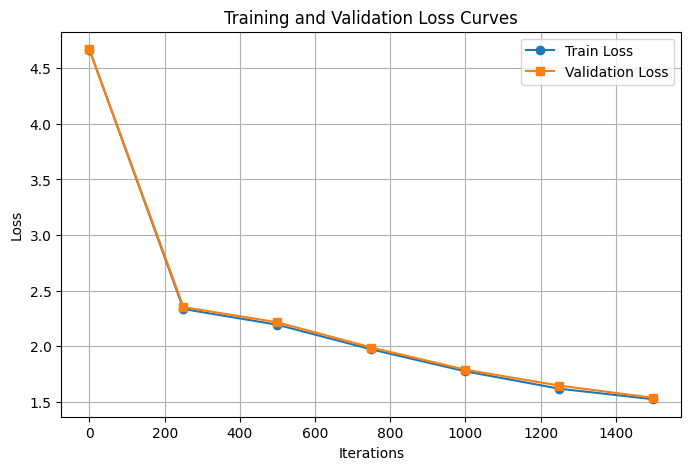

In [9]:
# Model Hyperparameters (Steps 5 & 10)
n_embd = 128
n_head = 4
n_layer = 4
dropout = 0.1
learning_rate = 3e-4
max_iters = 1500
eval_interval = 250
eval_iters = 50

model = TinyTransformer(vocab_size, n_embd, block_size, n_head, n_layer, dropout).to(device)
print(f"Model Parameter Count: {sum(p.numel() for p in model.parameters())/1e6:.2f}M parameters")

# Configure Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

# Training Loop (Step 6 & 7)
train_loss_history = []
val_loss_history = []
iters_history = []

print("\nStarting Training...")
start_time = time.time()

for iter in range(max_iters):
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        train_loss_history.append(losses['train'])
        val_loss_history.append(losses['val'])
        iters_history.append(iter)
        print(f"Step {iter:4d} | train loss {losses['train']:.4f} | val loss {losses['val']:.4f}")

    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print(f"Training finished in {(time.time() - start_time)/60:.2f} minutes.")

# Plot Loss Curves (Step 7)
plt.figure(figsize=(8, 5))
plt.plot(iters_history, train_loss_history, label='Train Loss', marker='o')
plt.plot(iters_history, val_loss_history, label='Validation Loss', marker='s')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# Step 8: Calculate validation loss and perplexity
model.eval()
with torch.no_grad():
    val_losses = []
    for _ in range(100):
        xb, yb = get_batch('val')
        _, loss = model(xb, yb)
        val_losses.append(loss.item())
    final_val_loss = sum(val_losses) / len(val_losses)
    perplexity = torch.exp(torch.tensor(final_val_loss)).item()

print(f"Final Evaluation Metrics:")
print(f" - Validation Loss: {final_val_loss:.4f}")
print(f" - Perplexity: {perplexity:.4f}")

Final Evaluation Metrics:
 - Validation Loss: 1.5412
 - Perplexity: 4.6700


In [11]:
# Step 9: Provide a starting prompt and generate text
prompt = "Once upon a time"
context = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)

model.eval()
generated_indices = model.generate(context, max_new_tokens=300, temperature=0.8)[0].tolist()
generated_story = decode(generated_indices)

print("--- Generated Story Output ---")
print(generated_story)

--- Generated Story Output ---
Once upon a timed to dog. They watcame and was saw for help to gan and then stoneted shantow looked.

"Ben, beack worry smilly the and smiled. It make he said, "Lucy, it playing could and canly and Jack the mord. The rish too, bub tell and then and Lily. He was very prach and and gaing and said Co could and the too


In [16]:
from google.colab import files

# 1. Save the story in Colab's current working directory
file_name = "generated_story.txt"
with open(file_name, "w", encoding="utf-8") as f:
    f.write(generated_story)

# 2. Trigger browser download to your local machine
files.download(file_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Step 11: Save the model parameters and configuration
checkpoint = {
    'model_state_dict': model.state_dict(),
    'vocab_size': vocab_size,
    'n_embd': n_embd,
    'block_size': block_size,
    'n_head': n_head,
    'n_layer': n_layer,
    'dropout': dropout,
    'chars': chars,
    'stoi': stoi,
    'itos': itos
}

torch.save(checkpoint, 'tiny_transformer_model.pt')
print("Model successfully saved as 'tiny_transformer_model.pt'!")

Model successfully saved as 'tiny_transformer_model.pt'!


In [14]:
import gradio as gr

def generate_story_gradio(prompt, max_tokens, temperature):
    if not prompt:
        prompt = "Once upon a time"

    context = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
    model.eval()
    with torch.no_grad():
        output_ids = model.generate(context, max_new_tokens=int(max_tokens), temperature=float(temperature))[0].tolist()
    return decode(output_ids)

demo = gr.Interface(
    fn=generate_story_gradio,
    inputs=[
        gr.Textbox(label="Starting Prompt", value="Once upon a time"),
        gr.Slider(minimum=50, maximum=500, value=200, step=25, label="Max Tokens"),
        gr.Slider(minimum=0.2, maximum=1.5, value=0.8, step=0.1, label="Temperature")
    ],
    outputs=gr.Textbox(label="Generated TinyStory"),
    title="Tiny Transformer Story Generator",
    description="Generate creative mini-stories using your trained custom decoder-only Transformer language model."
)

if __name__ == "__main__":
    demo.launch(inline=False, share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2aef50ad519387a74d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
